In [3]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

from src.utils.paths import PROCESSED_DIR, MODELS_DIR

SEED = 42

pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:.3f}".format)


In [4]:
train_df = pd.read_csv(PROCESSED_DIR / "features_train.csv")
eval_df = pd.read_csv(PROCESSED_DIR / "features_eval.csv")

print("train:", train_df.shape, "| eval:", eval_df.shape)

train: (4930, 31) | eval: (1056, 31)


In [5]:
train_df.head(3)

,customerID,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,Churn,is_first_year,has_internet,addon_count,autopay,spend_per_service,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,6918-UMQCG,0,0,0,5,1,0,0,0,0,0,1,0,0,80.200,0,1,1,1,0,26.733,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000
1,4140-MUHUG,1,0,0,3,1,0,0,0,1,0,1,0,1,86.850,1,1,1,2,0,21.712,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000
2,5570-PTWEH,0,1,0,3,1,1,0,0,0,0,0,0,1,75.150,1,1,1,0,1,37.575,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000


In [15]:
feature_cols = json.loads((MODELS_DIR / "feature_columns.json").read_text())
type(feature_cols), 

(list,)

In [16]:
print(len(feature_cols), "|", feature_cols)

29 | ['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'is_first_year', 'has_internet', 'addon_count', 'autopay', 'spend_per_service', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [17]:
print(train_df.columns)
print(len(train_df.columns))

Index(['customerID', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'MonthlyCharges', 'Churn', 'is_first_year',
       'has_internet', 'addon_count', 'autopay', 'spend_per_service',
       'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')
31


In [18]:
X_train = train_df[feature_cols]
y_train = train_df["Churn"]
X_eval = eval_df[feature_cols]
y_eval = eval_df["Churn"]

assert "customerID" not in feature_cols and "Churn" not in feature_cols
assert list(X_train.columns) == list(X_eval.columns)
assert X_train.isna().sum().sum() == 0 and X_eval.isna().sum().sum() == 0

print("Features:", X_train.shape[1])
print(f"Churn rate — train: {y_train.mean():.1%}, eval: {y_eval.mean():.1%}")

Features: 29
Churn rate — train: 26.5%, eval: 26.5%



## 4. Start with the do-nothing baseline
The dummy learns only which class is most common and predicts that class for everyone.

Here it will always predict stayed. It provides a reference, not a useful retention model.

`.fit(X_train, y_train)` means learn from training examples.

`.predict(X_eval)` means give a class label for customers in evaluation data.

In [19]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_eval)
print(f"Accuracy: {accuracy_score(y_eval, dummy_pred):.1%}")
print(f"Recall:   {recall_score(y_eval, dummy_pred):.1%}")

Accuracy: 73.5%
Recall:   0.0%


In [21]:
eval_df.Churn.value_counts(normalize=True)

Churn
0   0.735
1   0.265
Name: proportion, dtype: float64

**Read the result:** the dummy can get about three quarters of customers right while catching no churners. That is the imbalance problem we saw in EDA. Accuracy alone hides this failure.

## 5. Train logistic regression
Logistic regression learns a weight for each input and converts the combined score into a churn probability. For example, holding other inputs fixed, a feature with a positive coefficient raises the model’s churn score. The weights minimise log loss, which penalises confident wrong predictions.

We put a scaler and classifier in a small `Pipeline`. The scaler learns means and standard deviations from training data; it makes columns comparable in scale. Here it scales all 29 numeric inputs, including binary columns, which is a valid simple baseline. The classifier then learns from those scaled values.

The pipeline applies the same fitted scaler automatically during prediction and saves both steps together. `max_iter=2000 `nallows the optimiser enough iterations; it is not the number of models we train.

In [22]:
logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED))
])

logistic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['SeniorCitizen','Partner','Dependents',..., 'PaymentMethod_Credit card (automatic)','PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## See probabilities and decisions side by side
`.predict_proba()` returns two columns: probability of staying, then probability of churn.

`[:, 1]` selects the churn column. For example, 0.70 means the model estimates a 70% churn probability; that is an estimate, not a guarantee or a claim of calibrated probabilities.

`.predict()` gives the class decision using the model’s standard rule, corresponding to a 0.5 probability boundary for this binary model. We will explore changing that boundary later in this notebook.

In [23]:
logistic_prob = logistic.predict_proba(X_eval)[:, 1]
logistic_pred = logistic.predict(X_eval)

pd.DataFrame({
    "customerID": eval_df["customerID"],
    "actual_churn": y_eval,
    "churn_probability": logistic_prob,
    "predicted_churn": logistic_pred,
}).head(10)

,customerID,actual_churn,churn_probability,predicted_churn
0,9945-PSVIP,0,0.019,0
1,2325-NBPZG,0,0.627,1
2,4223-BKEOR,0,0.061,0
3,9919-FZDED,0,0.035,0
4,0488-GSLFR,1,0.706,1
5,1143-NMNQJ,1,0.829,1
6,3003-CMDUU,0,0.508,1
7,9256-JTBNZ,0,0.138,0
8,3627-FHKBK,1,0.468,0
9,9906-NHHVC,0,0.060,0


## 6. Train a decision tree
A tree learns a sequence of questions about the inputs. For example, it could separate new customers from long-standing customers, then split those groups by contract type.

It chooses splits that make the resulting groups less mixed in their churn outcomes.

Trees can capture interactions and nonlinear patterns, but a tree that grows too far can memorise the training data.

`max_depth=4` limits the tree to four split levels. `min_samples_leaf=30` stops it making leaves with only a few customers.

These are starting settings, not the result of a tuning search. Trees do not need feature scaling.

In [24]:
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=SEED)
tree.fit(X_train, y_train)

tree_prob = tree.predict_proba(X_eval)[:, 1]
tree_pred = tree.predict(X_eval)

## 7. Compare all three using the same measures
We use one short function so we calculate the same metrics for every model.
|Measure	| Plain meaning |
|---|---|
| Accuracy | Out of all customers, how many class decisions were right? |
| Precision	| Of those we flagged, how many actually churned? |
| Recall | Of all actual churners, how many did we catch? |
| F1 | A combined measure of precision and recall |
| ROC-AUC | How well does the model rank churners above stayers? |


For ROC-AUC we use probability scores, not class labels. A constant score gives AUC 0.5.

Precision is undefined when nobody is flagged; `zero_division=0` explicitly reports it as zero.

In [25]:
def evaluate(model):
    prediction = model.predict(X_eval)
    probability = model.predict_proba(X_eval)[:, 1]
    return {
        "accuracy": accuracy_score(y_eval, prediction),
        "precision": precision_score(y_eval, prediction, zero_division=0),
        "recall": recall_score(y_eval, prediction),
        "f1": f1_score(y_eval, prediction),
        "roc_auc": roc_auc_score(y_eval, probability),
    }

models = {"dummy": dummy, "logistic_regression": logistic, "decision_tree": tree}
results = pd.DataFrame({name: evaluate(model) for name, model in models.items()}).T

In [26]:
results


,accuracy,precision,recall,f1,roc_auc
dummy,0.735,0.000,0.000,0.000,0.500
logistic_regression,0.806,0.657,0.561,0.605,0.845
decision_tree,0.789,0.636,0.475,0.544,0.833


**How to read this table:** compare each learned model with the dummy, then compare the learned models with each other. Higher AUC means better ranking; higher recall means fewer missed churners at this decision rule.

A model does not automatically win every metric. The choice also depends on the cost of missed churners and false alarms.

These are development evaluation results, not our final holdout results.

## 8. Look at the mistakes
In each confusion matrix, rows show what actually happened and columns show our prediction.
- Top left: correctly predicted stayers.
- Top right: stayers wrongly flagged as churners, false positives.
- Bottom left: missed churners, false negatives.
- Bottom right: correctly identified churners, true positives.

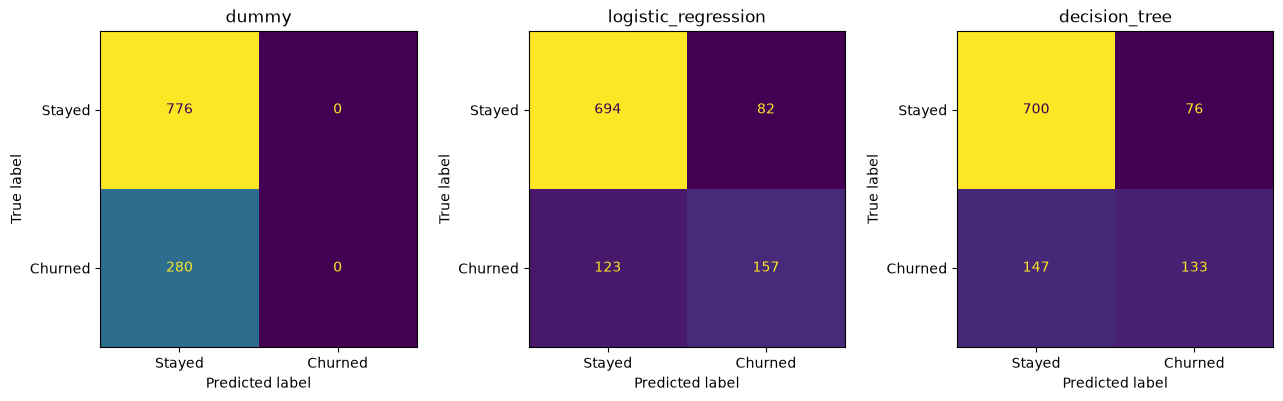

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_eval, model.predict(X_eval), display_labels=["Stayed", "Churned"],
        ax=ax, colorbar=False,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

**ROC AUC Curve:**
 The curve shows the trade-off between the share of churners caught and the share of stayers wrongly flagged as we vary the threshold.

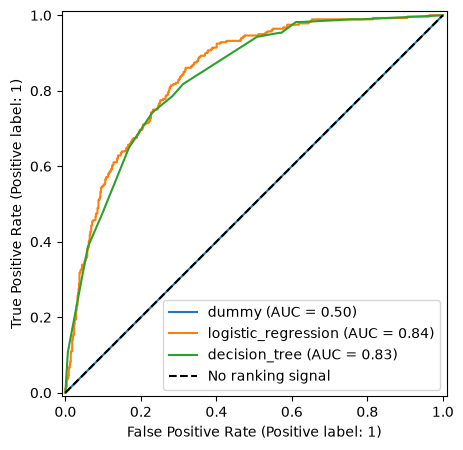

In [28]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    RocCurveDisplay.from_predictions(
        y_eval, model.predict_proba(X_eval)[:, 1], name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], "k--", label="No ranking signal")
ax.legend()
plt.show()

## 10. Check consistency with cross-validation
One split is only one view of the data. We divide the training rows into five folds. Each round fits a fresh model on four folds and scores it on the fifth. Stratification keeps approximately the same churn proportion in every fold.

The logistic pipeline refits its scaler inside each round. Nothing is fitted on evaluation rows. `cross_val_score()` fits fresh copies; it does not replace our models already fitted on the full training partition.

**Scope of this check:** notebook 02 already fitted the encoder on the full training partition and saved the feature tables. These CV results compare models with that feature representation held fixed; they are not a fold-by-fold assessment of the complete feature-engineering process. Keep the separate evaluation set for development checks and the holdout closed. When we evaluate the complete fitted preprocessing pipeline later, its encoder must also be fitted inside each training fold.

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_rows.append({
        "model": name,
        "mean_auc": scores.mean(),
        "std_auc": scores.std(ddof=1)
    })

cv_results = pd.DataFrame(cv_rows).set_index("model")
cv_results

,mean_auc,std_auc
model,,
dummy,0.500,0.000
logistic_regression,0.845,0.011
decision_tree,0.828,0.010


In [30]:
gaps = []
for name, model in models.items():
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    eval_auc = results.loc[name, "roc_auc"]
    gaps.append({
        "model": name,
        "train_auc": train_auc,
        "eval_auc": eval_auc,
        "gap": train_auc - eval_auc
    })

pd.DataFrame(gaps).set_index("model")

,train_auc,eval_auc,gap
model,,,
dummy,0.500,0.500,0.000
logistic_regression,0.849,0.845,0.004
decision_tree,0.840,0.833,0.008


In [31]:
threshold_rows = []

for threshold in [0.3, 0.5, 0.7]:
    prediction = (logistic_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "customers_flagged": prediction.sum(),
        "precision": precision_score(y_eval, prediction, zero_division=0),
        "recall": recall_score(y_eval, prediction),
    })

pd.DataFrame(threshold_rows)

,threshold,customers_flagged,precision,recall
0,0.300,425,0.515,0.782
1,0.500,239,0.657,0.561
2,0.700,86,0.733,0.225


## 12. Save the baseline models and comparison tables
Save both learned models so we can compare them with next week’s work. Saving the logistic pipeline also saves its fitted scaler. We leave our encoder and feature-column file from last class unchanged.

Input contract: these models accept the 29 already engineered and encoded columns in `feature_cols` order, not raw customer details. Preparing raw inputs for an API belongs to a later lesson. `baseline_results.csv` stores the evaluation comparison; `baseline_cv.csv` stores the CV summary.

In [32]:
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(logistic, MODELS_DIR / "baseline_logistic.joblib")
joblib.dump(tree, MODELS_DIR / "baseline_tree.joblib")
results.to_csv(PROCESSED_DIR / "baseline_results.csv")
cv_results.to_csv(PROCESSED_DIR / "baseline_cv.csv")
print("Saved both baselines and the comparison tables.")

Saved both baselines and the comparison tables.


## Check that a saved model still gives the same predictions
Reload it and compare ten probabilities. `assert_allclose` raises an error if they differ beyond a small numerical tolerance. Only load joblib files that come from a trusted source.

In [33]:
saved_logistic = joblib.load(MODELS_DIR / "baseline_logistic.joblib")
np.testing.assert_allclose(
    saved_logistic.predict_proba(X_eval.head(10))[:, 1],
    logistic_prob[:10]
)
print("Reloaded model gives the same predictions.")

Reloaded model gives the same predictions.
